# 02 · From the biological neuron to backpropagation (1943 → 1986), in code

**Lectures:** *History of Deep Learning* (04-08-2026) and *The Biological Neuron Analogy* (05-08-2026, Part B) · **Notes:** `../notes/01_history_of_deep_learning.md`, `../notes/02_ai_ml_dl_genai_and_the_neuron.md`

The history lecture is a timeline. Here we **run** its first four milestones:

| Year | Milestone | What we code |
|---|---|---|
| 1943 | McCulloch & Pitts: the first artificial neuron | a threshold neuron that computes AND, OR and NOT, with **no learning** |
| 1958 | Rosenblatt: the perceptron | the same neuron, but its weights **learn** from examples (synaptic plasticity) |
| 1969 | Minsky & Papert: the limits | the perceptron **fails on XOR**, which led to the first "AI winter" |
| 1986 | Rumelhart, Hinton & Williams: backpropagation | a **multi-layer** network trained by backpropagation **solves XOR** |

Along the way we map each part of the code to the **biological neuron** (dendrites, synapses, soma, threshold, axon). Runs in seconds.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])

## The mapping we'll keep using

| Biological neuron | Artificial neuron | In the code below |
|---|---|---|
| **dendrites** receive signals | **inputs** x₁, x₂, … | `x` |
| **synapse strength** | **weights** w₁, w₂, … | `w` |
| **soma** integrates (sums) the signals | **weighted sum + bias** | `z = w @ x + b` |
| **firing threshold / action potential** (all-or-nothing) | **activation function** | `1 if z >= 0 else 0` |
| **axon** carries the output on | **output** to the next layer | the return value |
| **synaptic plasticity** (learning) | **weight updates** | `w += ...` (from 1958 on) |

## 1943 · The McCulloch–Pitts neuron: logic from a threshold

Binary inputs, fixed weights, and a threshold θ: **fire (1) if the weighted sum reaches θ**. McCulloch and Pitts showed that such neurons can compute logic, which suggested that a brain-like network could, in principle, compute anything.

In [2]:
def mcculloch_pitts(x, w, theta):
    soma = np.dot(w, x)                 # integrate the incoming signals
    return int(soma >= theta)           # all-or-nothing firing

gates = {
    "AND": dict(w=[1, 1], theta=2),     # fires only if BOTH inputs fire
    "OR":  dict(w=[1, 1], theta=1),     # fires if AT LEAST ONE input fires
}
for name, p in gates.items():
    print(name, [mcculloch_pitts(x, **p) for x in X])
print("NOT", [mcculloch_pitts([x], w=[-1], theta=0) for x in [0, 1]], " (an inhibitory input: weight -1)")

AND [0, 0, 0, 1]
OR [0, 1, 1, 1]
NOT [1, 0]  (an inhibitory input: weight -1)


No learning happened: **a human chose** the weights and thresholds. That's 1943's limitation, and it's what the **perceptron** changed.

## 1958 · Rosenblatt's perceptron: the weights learn

Same neuron (weights, sum, threshold), plus a **learning rule** that adjusts the weights after every mistake: **w ← w + η·(y − ŷ)·x**. This is the artificial version of **synaptic plasticity**: connections that should have fired more get stronger. (`03_perceptron_from_scratch.ipynb` covers this in depth.)

In [3]:
def train_perceptron(X, y, eta=0.1, epochs=50):
    w, b, history = np.zeros(2), 0.0, []
    for epoch in range(epochs):
        mistakes = 0
        for xi, yi in zip(X, y):
            y_hat = int(np.dot(w, xi) + b >= 0)
            w += eta * (yi - y_hat) * xi        # synaptic plasticity
            b += eta * (yi - y_hat)
            mistakes += int(yi != y_hat)
        history.append(mistakes)
        if mistakes == 0:
            break
    return w, b, history

for name, y in [("AND", np.array([0, 0, 0, 1])), ("OR", np.array([0, 1, 1, 1]))]:
    w, b, hist = train_perceptron(X, y)
    print(f"{name}: learned w = {w}, b = {b:.1f} in {len(hist)} epochs -> outputs {[int(np.dot(w, x) + b >= 0) for x in X]}")

AND: learned w = [0.2 0.1], b = -0.2 in 4 epochs -> outputs [0, 0, 0, 1]
OR: learned w = [0.1 0.1], b = -0.1 in 4 epochs -> outputs [0, 1, 1, 1]


The perceptron **found weights for AND and OR by itself**. That was the excitement of 1958: a machine that learns from examples.

## 1969 · Minsky & Papert: the XOR problem → the AI winter

XOR mistakes per epoch: [3, 3, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4] ... still 4 mistakes after 50 epochs
outputs: [1, 1, 0, 0]  target: [0, 1, 1, 0]


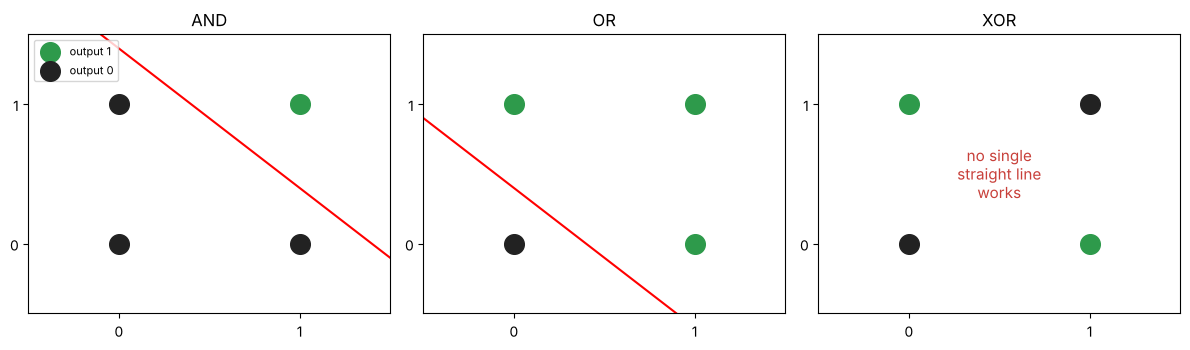

In [4]:
y_xor = np.array([0, 1, 1, 0])
w, b, hist = train_perceptron(X, y_xor, epochs=50)
print("XOR mistakes per epoch:", hist[:12], "... still", hist[-1], "mistakes after", len(hist), "epochs")
print("outputs:", [int(np.dot(w, x) + b >= 0) for x in X], " target:", y_xor.tolist())

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, (name, yy) in zip(axes, [("AND", [0, 0, 0, 1]), ("OR", [0, 1, 1, 1]), ("XOR", [0, 1, 1, 0])]):
    yy = np.array(yy)
    ax.scatter(*X[yy == 1].T, s=200, c="#2e9a4b", label="output 1"); ax.scatter(*X[yy == 0].T, s=200, c="#222", label="output 0")
    ax.set_xlim(-0.5, 1.5); ax.set_ylim(-0.5, 1.5); ax.set_title(name); ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
axes[0].plot([-0.5, 1.5], [1.9, -0.1], "r-"); axes[1].plot([-0.5, 1.2], [0.9, -0.8], "r-")
axes[2].text(0.5, 0.5, "no single\nstraight line\nworks", ha="center", va="center", color="#c8403a", fontsize=11)
axes[0].legend(loc="upper left", fontsize=8); plt.tight_layout(); plt.show()

A single perceptron draws **one straight line**. XOR's 1s sit on one diagonal and its 0s on the other, so no line separates them, and the perceptron keeps making mistakes forever. Minsky and Papert's book *Perceptrons* (1969) made this limitation famous, funding dried up, and the field entered the **AI winter**: researchers moved to rule-based expert systems.

## 1986 · Backpropagation: multi-layer networks learn XOR

The fix needed two things:
1. **Hidden layers**, so the network can bend its decision boundary.
2. A way to **train** them. The step function's slope is 0, so it gives no learning signal, and nobody knew how much each hidden neuron was to blame for an error.

**Backpropagation** (Rumelhart, Hinton & Williams, 1986) solved part 2: use a **smooth** activation (sigmoid), and pass the error **backwards** layer by layer with the chain rule, giving every weight its share of the blame. Here it is from scratch in NumPy (no deep-learning library), so nothing is hidden.

outputs after training: [0.016 0.988 0.981 0.017] -> rounded [0, 1, 1, 0]  target [0, 1, 1, 0]


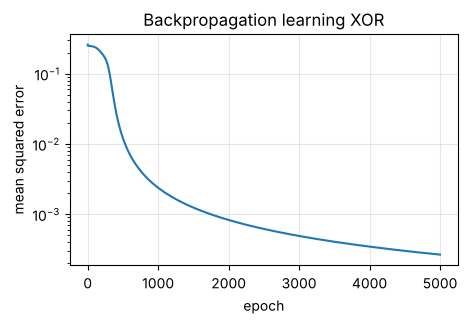

In [5]:
rng = np.random.default_rng(1)
sigmoid = lambda z: 1 / (1 + np.exp(-z))
W1, b1 = rng.normal(0, 1, (2, 3)), np.zeros(3)      # input (2) -> hidden (3)
W2, b2 = rng.normal(0, 1, (3, 1)), np.zeros(1)      # hidden (3) -> output (1)
Y = y_xor.reshape(-1, 1); eta = 1.0; losses = []
for epoch in range(5000):
    # forward pass: signals flow input -> hidden -> output (dendrites -> soma -> axon -> next neuron)
    H = sigmoid(X @ W1 + b1)
    out = sigmoid(H @ W2 + b2)
    losses.append(np.mean((out - Y) ** 2))
    # backward pass: the error flows output -> hidden, each weight gets its share of the blame
    d_out = (out - Y) * out * (1 - out)              # chain rule through the output sigmoid
    d_hid = (d_out @ W2.T) * H * (1 - H)             # ... and back through the hidden sigmoids
    W2 -= eta * H.T @ d_out;  b2 -= eta * d_out.sum(0)
    W1 -= eta * X.T @ d_hid;  b1 -= eta * d_hid.sum(0)
print("outputs after training:", out.ravel().round(3), "-> rounded", (out.ravel() > 0.5).astype(int).tolist(), " target", y_xor.tolist())
plt.figure(figsize=(5, 3)); plt.plot(losses); plt.yscale("log"); plt.xlabel("epoch"); plt.ylabel("mean squared error")
plt.title("Backpropagation learning XOR"); plt.grid(alpha=0.3); plt.show()

**XOR solved.** The two-layer network learned it from examples using backpropagation, which became the standard training algorithm and remains so today, inside every PyTorch `loss.backward()`.

## What happened next (the rest of the timeline)

| Year | Milestone | Where you meet it |
|---|---|---|
| 1998 | **LeNet-5** (LeCun): CNNs read handwritten digits and bank cheques | CV course Week 2–3 |
| 2006 | **Deep Belief Networks** (Hinton): layer-wise pre-training makes deep nets trainable | the start of "modern" deep learning |
| 2012 | **AlexNet** (Krizhevsky, Sutskever, Hinton): GPUs + **ReLU** + **Dropout** win ImageNet | notebooks 04 and 05 here |
| 2014 | **GANs** (Goodfellow): generator vs discriminator | CV course Week 4 |
| 2017 | **Transformers** ("Attention Is All You Need", Google) | the basis of LLMs |
| 2020– | **Foundation models & Generative AI** (GPT, Llama, Gemini, Claude, Stable Diffusion) | notebook 01's tiny generative model is the toy version |

## Where the biological analogy stops

The code above captures the **computational principle** (weighted inputs → sum → threshold → output, with adjustable connections). It ignores almost everything else about real neurons:

| | Biological | Our code |
|---|---|---|
| signal | electrochemical spikes, neurotransmitters | floating-point numbers |
| timing | asynchronous, continuous time | synchronous steps |
| learning | biochemical plasticity, not fully understood | an exact formula (backpropagation + gradient descent) |
| scale | ~86 billion neurons, ~100 trillion synapses, ~20 watts | 4 neurons (3 hidden + 1 output) and 13 learnable numbers here |

## ✅ Check yourself
1. Match: dendrites, synapse, soma, firing threshold, axon, plasticity → ? *(inputs, weights, weighted sum + bias, activation function, output, weight updates)*
2. What could the 1943 neuron do, and what couldn't it do? *(compute logic with hand-set weights; it couldn't learn)*
3. What did the perceptron add in 1958? *(a learning rule that adjusts the weights from examples)*
4. Why did XOR cause an "AI winter"? *(a single-layer perceptron provably can't learn it, which undermined confidence and funding)*
5. What two things were needed to solve XOR, and which 1986 algorithm provided the training part? *(hidden layers + a way to train them; backpropagation with smooth activations)*